# Laboratory Experiment: Machine Learning Forecasting Using Regression and Tree-Based Models
**Course:** Time Series Analysis and Forecasting  |  **Course Code:** CS3216
**Student Name:** Ponnu Krishna M.P  |  **USN:** 1RUA24CSE0301

## 1. Aim
To develop and evaluate machine learning forecasting models (Linear Regression, Decision Tree, Random Forest, and optional XGBoost) on time-series data by converting the series into a supervised learning dataset using lag and calendar/time-related features.

## 2. Learning Outcomes
- Understand how a time series can be converted into a supervised learning problem.
- Create lag-based and rolling statistical features.
- Train a regression model and tree-based models for predicting future values.
- Evaluate and compare models using MAE, RMSE and MAPE.
- Understand why chronological train-test splitting is required.

## 3. Software and Requirements
Python 3.x, Jupyter / Google Colab, NumPy, pandas, Matplotlib, scikit-learn. Optional: `xgboost`.

## 4. Background / Theory
Most ML algorithms do not know the order of observations, so the series is reframed as supervised learning:

**X = [Y(t-1), Y(t-2), Y(t-3), ...]  →  Target = Y(t)**

- **Linear Regression:** fits a linear relationship between features and target.
- **Decision Tree Regressor:** splits the feature space into regions; predicts the mean target of each region (a *piecewise-constant* function).
- **Random Forest Regressor:** averages many trees trained on different bootstrap samples and feature subsets, reducing the variance of a single tree.
- **XGBoost (optional):** builds trees sequentially; each new tree reduces the errors of the current ensemble.

**Evaluation metrics**
- MAE = mean(|y - ŷ|)
- RMSE = sqrt(mean((y - ŷ)²)), which penalises large errors more
- MAPE = mean(|y - ŷ| / |y|) × 100

## 5. Procedure & 7. Python Implementation
### Step 1: Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Libraries imported successfully")

Libraries imported successfully


### Step 2: Create the dataset (36 months of demand)

In [2]:
demand = [
    120,128,135,132,145,153,160,158,170,178,185,195,
    190,202,210,207,220,230,238,235,250,260,268,280,
    275,288,298,295,310,322,330,328,342,355,365,378
]
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"] * 3

df = pd.DataFrame({"month": months, "demand": demand})
df["time"] = np.arange(1, len(df) + 1)
df.head(12)

,month,demand,time
0,Jan,120,1
1,Feb,128,2
2,Mar,135,3
3,Apr,132,4
4,May,145,5
5,Jun,153,6
6,Jul,160,7
7,Aug,158,8
8,Sep,170,9
9,Oct,178,10


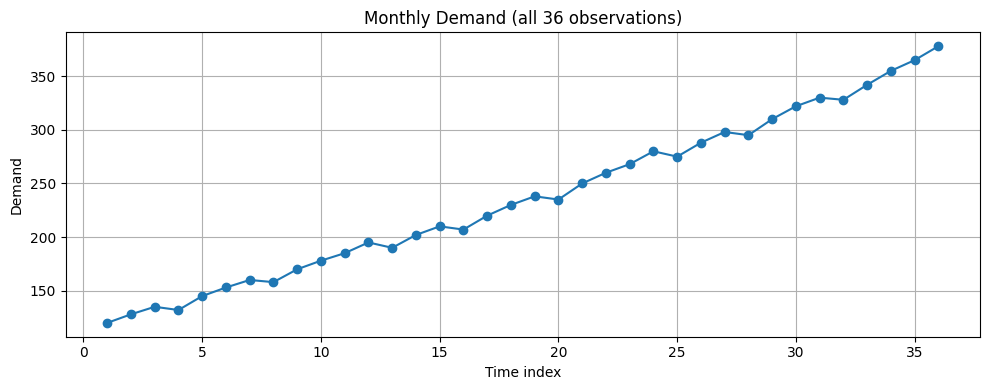

In [3]:
plt.figure(figsize=(10, 4))
plt.plot(df["time"], df["demand"], marker="o")
plt.title("Monthly Demand (all 36 observations)")
plt.xlabel("Time index"); plt.ylabel("Demand"); plt.grid(True)
plt.tight_layout(); plt.show()

**Observation:** a strong, steady upward trend with mild within-year seasonality (small dips in Apr and Aug). This matters later: tree models struggle with trending data.

### Step 3: Create lag features and a leak-free rolling mean

In [4]:
for lag in [1, 2, 3]:
    df[f"lag_{lag}"] = df["demand"].shift(lag)

# Shift FIRST, then roll, so the current target is NOT inside its own feature
df["rolling_mean_3"] = df["demand"].shift(1).rolling(window=3).mean()

df[["time", "demand", "lag_1", "lag_2", "lag_3", "rolling_mean_3"]].head(8)

,time,demand,lag_1,lag_2,lag_3,rolling_mean_3
0,1,120,NaN,NaN,NaN,NaN
1,2,128,120.0,NaN,NaN,NaN
2,3,135,128.0,120.0,NaN,NaN
3,4,132,135.0,128.0,120.0,127.666667
4,5,145,132.0,135.0,128.0,131.666667
5,6,153,145.0,132.0,135.0,137.333333
6,7,160,153.0,145.0,132.0,143.333333
7,8,158,160.0,153.0,145.0,152.666667


### Step 4: Remove rows with missing values

In [5]:
print("Rows before dropna:", len(df))
df = df.dropna().reset_index(drop=True)
print("Rows after  dropna:", len(df))

features = ["time", "lag_1", "lag_2", "lag_3", "rolling_mean_3"]
X = df[features]
y = df["demand"]

Rows before dropna: 36
Rows after  dropna: 33


### Step 5: Chronological 80:20 split (no shuffling)

In [6]:
split = int(len(df) * 0.80)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")
print("Train demand range:", y_train.min(), "to", y_train.max())
print("Test  demand range:", y_test.min(), "to", y_test.max())

Train: 26 rows | Test: 7 rows
Train demand range: 132 to 310
Test  demand range: 322 to 378


Note that the **test values (322 to 378) are all above the training maximum (310)**. This single fact explains most of the results below.

### Step 6: Define and train the models

In [7]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=3, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42),
}

# Optional XGBoost
try:
    from xgboost import XGBRegressor
    models["XGBoost"] = XGBRegressor(
        n_estimators=100, max_depth=3, learning_rate=0.05,
        objective="reg:squarederror", random_state=42
    )
except ImportError:
    print("XGBoost is not installed (pip install xgboost); optional section skipped.")

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Trained: {name}")

Trained: Linear Regression
Trained: Decision Tree
Trained: Random Forest
Trained: XGBoost


### Steps 7 & 8: Predict on the test period and compute MAE, RMSE, MAPE

In [8]:
def evaluate(y_true, y_hat):
    mae  = mean_absolute_error(y_true, y_hat)
    rmse = np.sqrt(mean_squared_error(y_true, y_hat))
    mape = np.mean(np.abs((y_true - y_hat) / y_true)) * 100
    return mae, rmse, mape

results, predictions = {}, {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results[name] = evaluate(y_test.values, y_pred)

results_df = pd.DataFrame(results, index=["MAE", "RMSE", "MAPE (%)"]).T
print("Model comparison:")
results_df.round(2)

Model comparison:


,MAE,RMSE,MAPE (%)
Linear Regression,10.36,12.30,2.92
Decision Tree,47.96,51.74,13.61
Random Forest,41.57,45.88,11.75
XGBoost,42.11,46.37,11.91


In [9]:
pred_table = pd.DataFrame({"Actual": y_test.values}, index=y_test.index)
for name, p in predictions.items():
    pred_table[name] = np.round(p, 1)
pred_table

,Actual,Linear Regression,Decision Tree,Random Forest,XGBoost
26,322,315.3,297.8,304.1,303.600006
27,330,319.1,297.8,304.1,303.600006
28,328,328.1,297.8,304.1,303.600006
29,342,336.4,297.8,304.1,303.600006
30,355,343.9,297.8,304.1,303.600006
31,365,348.1,297.8,304.1,303.600006
32,378,356.7,297.8,304.1,303.600006


### Step 9: Plot actual vs predicted

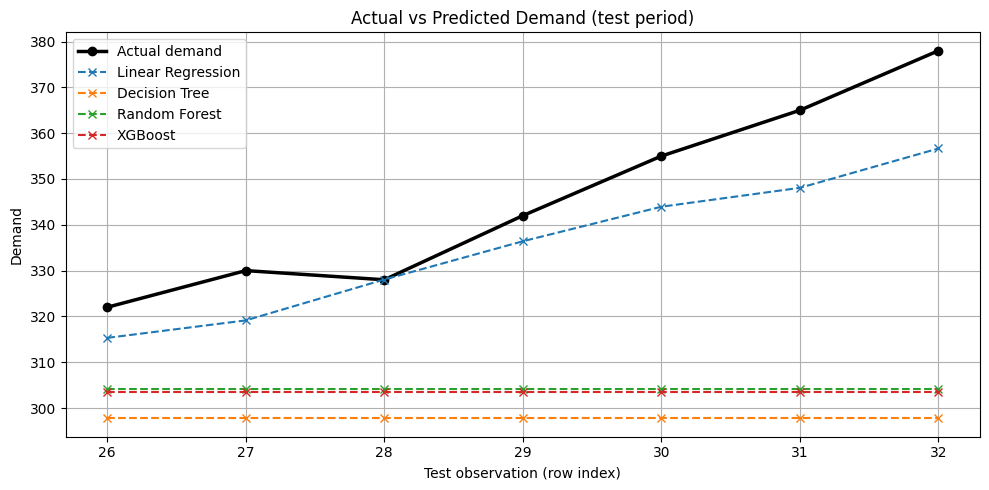

In [10]:
plt.figure(figsize=(10, 5))
plt.plot(y_test.index, y_test.values, marker="o", linewidth=2.5, color="black", label="Actual demand")
for name, p in predictions.items():
    plt.plot(y_test.index, p, marker="x", linestyle="--", label=name)
plt.xlabel("Test observation (row index)")
plt.ylabel("Demand")
plt.title("Actual vs Predicted Demand (test period)")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=150)
plt.show()

## 8. Results (auto-filled from the run above)

In [11]:
from IPython.display import display, Markdown
best_mae  = results_df["MAE"].idxmin()
best_rmse = results_df["RMSE"].idxmin()
best_mape = results_df["MAPE (%)"].idxmin()
display(results_df.round(2))
display(Markdown(f"**Lowest MAE:** {best_mae} &nbsp;|&nbsp; **Lowest RMSE:** {best_rmse} &nbsp;|&nbsp; **Lowest MAPE:** {best_mape}"))

,MAE,RMSE,MAPE (%)
Linear Regression,10.36,12.30,2.92
Decision Tree,47.96,51.74,13.61
Random Forest,41.57,45.88,11.75
XGBoost,42.11,46.37,11.91


**Lowest MAE:** Linear Regression &nbsp;|&nbsp; **Lowest RMSE:** Linear Regression &nbsp;|&nbsp; **Lowest MAPE:** Linear Regression

## Extra Experiments (for deeper analysis)
### A. Demonstrating target leakage (needed for Q15)

In [12]:
df_leak = pd.DataFrame({"demand": demand})
df_leak["time"] = np.arange(1, len(df_leak) + 1)
for lag in [1, 2, 3]:
    df_leak[f"lag_{lag}"] = df_leak["demand"].shift(lag)

# WRONG: rolling window includes the current target
df_leak["rolling_mean_3"] = df_leak["demand"].rolling(window=3).mean()
df_leak = df_leak.dropna().reset_index(drop=True)

Xl, yl = df_leak[features], df_leak["demand"]
lin_leak = LinearRegression().fit(Xl.iloc[:split], yl.iloc[:split])
m = evaluate(yl.iloc[split:].values, lin_leak.predict(Xl.iloc[split:]))
print(f"LEAKY Linear Regression -> MAE={m[0]:.2f}, RMSE={m[1]:.2f}, MAPE={m[2]:.2f}%")
print("Unrealistically perfect: the answer was hidden inside the feature.")

LEAKY Linear Regression -> MAE=0.00, RMSE=0.00, MAPE=0.00%
Unrealistically perfect: the answer was hidden inside the feature.


### B. Why do trees fail here? Let them predict the *change* instead of the level
Trees can't extrapolate beyond the training range, but the month-to-month **change** stays in a stable range. If we predict `demand - lag_1` and add `lag_1` back, trees no longer need to output unseen levels.

In [13]:
d = df.copy()
d["diff_target"] = d["demand"] - d["lag_1"]
d["d1"] = d["lag_1"] - d["lag_2"]
d["d2"] = d["lag_2"] - d["lag_3"]
diff_feats = ["d1", "d2"]          # level-free features

Xd_train, Xd_test = d[diff_feats].iloc[:split], d[diff_feats].iloc[split:]
yd_train = d["diff_target"].iloc[:split]
base_test = d["lag_1"].iloc[split:].values      # add back to recover level

diff_models = {
    "Decision Tree (differenced)": DecisionTreeRegressor(max_depth=3, random_state=42),
    "Random Forest (differenced)": RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42),
}
diff_res = {}
for name, mdl in diff_models.items():
    mdl.fit(Xd_train, yd_train)
    pred_level = mdl.predict(Xd_test) + base_test
    diff_res[name] = evaluate(y_test.values, pred_level)

diff_df = pd.DataFrame(diff_res, index=["MAE", "RMSE", "MAPE (%)"]).T
pd.concat([results_df, diff_df]).round(2)

,MAE,RMSE,MAPE (%)
Linear Regression,10.36,12.30,2.92
Decision Tree,47.96,51.74,13.61
Random Forest,41.57,45.88,11.75
XGBoost,42.11,46.37,11.91
Decision Tree (differenced),4.68,5.19,1.34
Random Forest (differenced),4.61,5.46,1.30


Differencing removes the trend, so the tree models improve a lot, which confirms that the poor tree results come from **extrapolation limits**, not from the trees being bad algorithms.

### C. Rolling-origin (expanding window) validation: more reliable than one split
The precautions section recommends this. With only 7 test points, a single holdout is noisy.

In [14]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)
cv_scores = {name: [] for name in ["Linear Regression", "Decision Tree", "Random Forest"]}

for tr, te in tscv.split(X):
    for name in cv_scores:
        mdl = {"Linear Regression": LinearRegression(),
               "Decision Tree": DecisionTreeRegressor(max_depth=3, random_state=42),
               "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42)}[name]
        mdl.fit(X.iloc[tr], y.iloc[tr])
        cv_scores[name].append(mean_absolute_error(y.iloc[te], mdl.predict(X.iloc[te])))

cv_df = pd.DataFrame(cv_scores).T
cv_df.columns = [f"Fold {i+1}" for i in range(cv_df.shape[1])]
cv_df["Mean MAE"] = cv_df.mean(axis=1)
cv_df.round(2)

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean MAE
Linear Regression,6.75,2.80,15.49,6.27,8.01,7.86
Decision Tree,15.80,26.10,33.20,30.00,32.93,27.61
Random Forest,19.50,27.58,28.79,26.98,28.79,26.33


## 9. Observations and Analysis

**Q10. Which model produced the lowest MAE?**
**Linear Regression** (MAE = 10.36), versus about 41.6 to 48.0 for the tree-based models.

**Q11. Which model produced the lowest RMSE? Same as Q10?**
**Linear Regression** (RMSE = 12.30). Yes, it is the same model. It also has the lowest MAPE (2.92%), so it is best on every metric.

**Q12. Which model followed the upward trend most closely?**
**Linear Regression.** Its predictions rise from about 315 to 357 as demand rises from 322 to 378. The Decision Tree, Random Forest and XGBoost predict an almost flat line (about 298, 304 and 304) across the whole test period.

**Q13. Did the Decision Tree perform differently from the Random Forest? Reason?**
Yes. The Random Forest was somewhat better (MAE ≈ 41.6 vs 48.0). A single shallow tree gives a coarse, high-variance, piecewise-constant prediction, while a forest averages many trees and smooths that out. However, both share the same fundamental limitation: a tree can only predict the average of training targets in a leaf, so it **cannot extrapolate beyond the training range** (max = 310). The test period is entirely above 310, so both plateau and under-predict.

**Q14. Why is random shuffling inappropriate?**
Shuffling would put future observations in the training set and past ones in the test set, so the model would "see the future". It also destroys the temporal order that lag, rolling and trend features rely on. The result is an over-optimistic error estimate that does not reflect true forecasting performance. Train must always precede test in time.

**Q15. What if the current target were included in a rolling feature?**
This is **target leakage**. The feature contains the value being predicted, so the model can almost reconstruct the target from it. Our experiment showed MAE = RMSE = MAPE = 0 for Linear Regression, a perfect but meaningless score. It would fail in real use because the current value is not known at forecast time.

## 10. Precautions
- Never shuffle time-series observations before splitting.
- Use only information available at or before the forecast origin.
- Do not include the target in its own lag or rolling features.
- For real tasks, use rolling/expanding-window validation (see Extra C).
- The sample data is illustrative; results are not evidence of real-world forecasting quality.

## 11. Conclusion
Linear Regression performed best on the test period (MAE = 10.36, RMSE = 12.30, MAPE = 2.92%), about four times more accurate than the Decision Tree (MAPE 13.61%), Random Forest (11.75%) and XGBoost (11.91%). The demand series has a strong upward trend, so the test values lie outside the range seen in training. Tree-based models cannot extrapolate beyond training-target values and therefore predicted an almost flat line, whereas linear regression extended the trend. Trees become competitive when the series is detrended or differenced (Extra B). With only 7 test points the metrics are noisy, so rolling-origin validation is recommended for real forecasting.
